# Import and predefining

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn.functional as F
from sklearn import set_config
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, random_split
from torchvision import datasets, models, transforms

set_config(display="text")

random_state = 42

torch.manual_seed(random_state)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [2]:
from dataclasses import dataclass


@dataclass
class ModelResult:
    name: str
    confusion_matrix: np.ndarray
    accuracy_score: float

    def __sub__(self, other) -> "ModelResult":
        if type(other) != type(self):
            raise NotImplementedError

        model_result = ModelResult(
            name=self.name + other.name,
            confusion_matrix=self.confusion_matrix - other.confusion_matrix,
            accuracy_score=self.accuracy_score - other.accuracy_score,
        )
        return model_result

In [3]:
def plot_heatmap(
    dataframe: pd.DataFrame | np.ndarray,
    figsize: tuple[int, int] = (6, 5),
    cmap: str | None = None,
    vmin: float | None = None,
    vmax: float | None = None,
    rotation: int = 45,
    xticklabels: list[str] | bool = True,
    yticklabels: list[str] | bool = True,
    title_name: str | None = None,
    ax: plt.Axes | None = None,  # pyright: ignore[reportPrivateImportUsage]
) -> None:
    if ax is None:
        plt.figure(figsize=figsize)

    sns.heatmap(
        dataframe,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        linewidths=0.5,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 7},
        xticklabels=xticklabels,
        yticklabels=yticklabels,
        ax=ax,
    )

    if ax is None:
        plt.xticks(rotation=rotation, ha="right", fontsize=9)
        plt.yticks(rotation=0, fontsize=9)
        if title_name:
            plt.title(title_name)
        plt.show()
    else:
        ax.tick_params(axis="x", rotation=rotation, labelsize=9)
        ax.tick_params(axis="y", rotation=0, labelsize=9)
        if title_name:
            ax.set_title(title_name)


def plot_table(
    cellText: np.ndarray | pd.DataFrame,
    rowLabels: list | None = None,
    colLabels: list | None = None,
    title_name: str | None = None,
    fontsize: int = 10,
    scale: tuple[float, float] = (1.7, 1.5),
    figsize: tuple[int, int] = (8, 3),
) -> None:
    fig, ax = plt.subplots(figsize=figsize)
    ax.axis("off")

    table = ax.table(
        cellText=cellText,
        rowLabels=rowLabels,
        colLabels=colLabels,
        cellLoc="center",
        loc="center",
    )

    table.auto_set_font_size(False)
    table.set_fontsize(fontsize)
    table.scale(*scale)
    if title_name:
        plt.title(title_name)
    plt.show()

# 1. Повнозв'язані нейронні мережі
1. Візьміть датасет, з яким ви працювали в лабораторній роботі №1.
1. Побудуйте повнозв'язану нейронну мережу (MLP) для задачі класифікації.
1. Навчіть модель на тренувальній вибірці та оцініть її якість на тестовій.
1. Побудуйте learning curves (train/validation loss) та проаналізуйте процес навчання моделі. Чи спостерігається перенавчання?
1. Порівняйте результати нейронної мережі з результатами класичних алгоритмів машинного навчання з Lab 1.
1. Зробіть висновки.

## Візьміть датасет, з яким ви працювали в лабораторній роботі №1

In [4]:
label_encoder_lab_1 = LabelEncoder()
scaler = StandardScaler()
datapath_lab_1 = Path("../lab1/data/Date_Fruit_Datasets.xlsx")
raw_data_lab_1 = pd.read_excel(datapath_lab_1)

target_name = "Class"
features_lab_1 = raw_data_lab_1.drop(target_name, axis=1)
target_lab_1 = raw_data_lab_1[target_name]

target_encoded_lab_1 = label_encoder_lab_1.fit_transform(target_lab_1)

X_train_lab_1, X_test_lab_1, y_train_lab_1, y_test_lab_1 = train_test_split(
    features_lab_1,
    target_encoded_lab_1,
    random_state=random_state,
    test_size=0.25,
    stratify=target_encoded_lab_1,
)

X_train_lab_1_scaled = scaler.fit_transform(X_train_lab_1)
X_test_lab_1_scaled = scaler.transform(X_test_lab_1)

In [5]:
(
    X_train_lab_1_scaled.shape,
    X_test_lab_1_scaled.shape,
    y_train_lab_1.shape,
    y_test_lab_1.shape,
)

((673, 34), (225, 34), (673,), (225,))

In [6]:
len(label_encoder_lab_1.classes_)

7

## Побудуйте повнозв'язану нейронну мережу (MLP) для задачі класифікації

In [7]:
class MLP(nn.Module):
    def __init__(self, in_features: int, out_features: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, out_features),  # logits
        )

    def forward(self, x):
        logits = self.net(x)  # [B, 34] -> [B, 7]
        return logits  # [B, 7]


in_features = X_train_lab_1_scaled.shape[-1]
out_features = len(label_encoder_lab_1.classes_)
model = MLP(in_features, out_features).to(device)
print(model)

MLP(
  (net): Sequential(
    (0): Linear(in_features=34, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=7, bias=True)
  )
)


## Навчіть модель на тренувальній вибірці та оцініть її якість на тестовій

In [ ]:
model = MLP(in_features, out_features).to(device)

num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Trainable params:", num_params)
print()

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-3)

patience = 10
n_epochs = 100
best_model_path = "best_model.pth"
batch_size = 32

X_not_test_t = torch.as_tensor(X_train_lab_1_scaled, dtype=torch.float32)
y_not_test_t = torch.as_tensor(y_train_lab_1, dtype=torch.long)

X_train_t, X_val_t, y_train_t, y_val_t = train_test_split(
    X_not_test_t,
    y_not_test_t,
    test_size=0.2,
    stratify=y_not_test_t,
    random_state=random_state,
)

train_loader = DataLoader(
    TensorDataset(X_train_t.to(device), y_train_t.to(device)),
    batch_size=batch_size,
    shuffle=True,
)
val_loader = DataLoader(
    TensorDataset(X_val_t.to(device), y_val_t.to(device)),
    batch_size=batch_size,
    shuffle=False,
)

X_train_len = len(X_train_t)
X_val_len = len(X_val_t)


def train_and_eval(
    model,
    criterion,
    optimizer,
    patience: int,
    n_epochs: int,
    best_model_path: str,
    X_train_len,
    X_val_len,
    train_loader,
    val_loader,
    device: str | torch.Device,
) -> tuple[list[float], list[float], list[float], list[float]]:
    best_val_loss = float("inf")
    epochs_no_improve = 0
    train_loss_history: list[float] = []
    train_accuracy_history: list[float] = []
    val_loss_history: list[float] = []
    val_accuracy_history: list[float] = []
    for epoch in range(n_epochs):
        # --- train ---
        model.train()
        train_loss = 0.0
        train_accuracy = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            train_accuracy += (out.argmax(dim=1) == y).sum().item()
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * x.size(0)
        train_loss /= X_train_len
        train_accuracy /= X_train_len

        # --- validation ---
        model.eval()
        val_loss = 0.0
        val_accuracy = 0.0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                out = model(x)
                loss = criterion(out, y)
                val_accuracy += (out.argmax(dim=1) == y).sum().item()
                val_loss += loss.item() * x.size(0)
        val_loss /= X_val_len
        val_accuracy /= X_val_len

        train_loss_history.append(train_loss)
        train_accuracy_history.append(train_accuracy)
        val_loss_history.append(val_loss)
        val_accuracy_history.append(val_accuracy)
        print(
            f"[{epoch + 1:02d}] train_loss={train_loss:.4f} | train_accuracy={train_accuracy:.4f} | val_loss={val_loss:.4f} | val_accuracy={val_accuracy:.4f}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            epochs_no_improve = 0
            torch.save(model.state_dict(), best_model_path)
            print("Saved best model")
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print("Early stopping epoch: ", epoch)
                break

    return (
        train_loss_history,
        train_accuracy_history,
        val_loss_history,
        val_accuracy_history,
    )


train_loss_history, train_accuracy_history, val_loss_history, val_accuracy_history = (
    train_and_eval(
        model,
        criterion,
        optimizer,
        patience,
        n_epochs,
        best_model_path,
        X_train_len,
        X_val_len,
        train_loader,
        val_loader,
        device,
    )
)

Trainable params: 13191



[01] train_loss=1.6190 | train_accuracy=0.5603 | val_loss=1.1772 | val_accuracy=0.6912
Saved best model
[02] train_loss=0.9781 | train_accuracy=0.6975 | val_loss=0.7089 | val_accuracy=0.7206
Saved best model
[03] train_loss=0.6458 | train_accuracy=0.7620 | val_loss=0.5237 | val_accuracy=0.7941
Saved best model
[04] train_loss=0.4822 | train_accuracy=0.8165 | val_loss=0.4362 | val_accuracy=0.8088
Saved best model
[05] train_loss=0.4093 | train_accuracy=0.8529 | val_loss=0.3869 | val_accuracy=0.8235
Saved best model
[06] train_loss=0.3541 | train_accuracy=0.8826 | val_loss=0.3495 | val_accuracy=0.8382
Saved best model
[07] train_loss=0.3213 | train_accuracy=0.8926 | val_loss=0.3011 | val_accuracy=0.8676
Saved best model
[08] train_loss=0.2995 | train_accuracy=0.9008 | val_loss=0.2878 | val_accuracy=0.8824
Saved best model
[09] train_loss=0.2731 | train_accuracy=0.9091 | val_loss=0.2597 | val_accuracy=0.8971
Saved best model
[10] train_loss=0.2567 | train_accuracy=0.9174 | val_loss=0.2344

## Побудуйте learning curves (train/validation loss) та проаналізуйте процес навчання моделі. Чи спостерігається перенавчання?

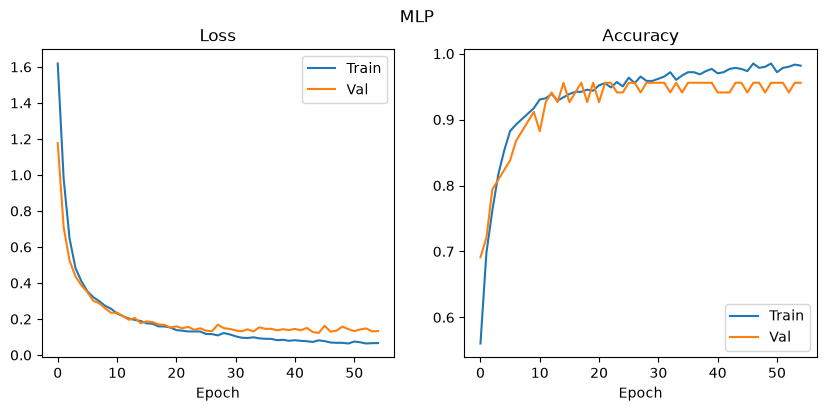

In [9]:
def plot_learning_curves(
    train_loss_history: list[float],
    train_accuracy_history: list[float],
    val_loss_history: list[float],
    val_accuracy_history: list[float],
    title: str,
):
    fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(10, 4))

    sns.lineplot(train_loss_history, label="Train", ax=ax1)
    sns.lineplot(val_loss_history, label="Val", ax=ax1)

    sns.lineplot(train_accuracy_history, label="Train", ax=ax2)
    sns.lineplot(val_accuracy_history, label="Val", ax=ax2)

    ax1.set_title("Loss")
    ax1.set_xlabel("Epoch")

    ax2.set_title("Accuracy")
    ax2.set_xlabel("Epoch")

    plt.suptitle(title)
    plt.show()


plot_learning_curves(
    train_loss_history,
    train_accuracy_history,
    val_loss_history,
    val_accuracy_history,
    title="MLP",
)

Спостерігається перенавчання починаючи з епохи 46 і до 54, де зупиняється через ранню зупинку.

## Порівняйте результати нейронної мережі з результатами класичних алгоритмів машинного навчання з Lab 1

In [10]:
pca_svc = Pipeline(
    [
        ("pca", PCA(n_components=9, random_state=random_state)),
        ("svc", SVC(C=10, gamma=0.01, kernel="rbf", random_state=random_state)),
    ]
)
pca_svc.fit(X_train_t.detach().numpy(), y_train_t.detach().numpy())
old_pred = pca_svc.predict(X_test_lab_1_scaled)

In [11]:
model.load_state_dict(torch.load(best_model_path, weights_only=True))

X_test_t = torch.as_tensor(X_test_lab_1_scaled, dtype=torch.float32, device=device)
y_test_t = torch.as_tensor(y_test_lab_1, dtype=torch.long, device=device)

model.eval()
with torch.no_grad():
    y_pred = model(X_test_t).argmax(dim=1).cpu().numpy()

labels = label_encoder_lab_1.classes_

mlp_score = accuracy_score(y_test_lab_1, y_pred)
print(f"MLP Test accuracy: {mlp_score:.4f}")
mlp_report = classification_report(y_test_lab_1, y_pred, target_names=labels)
print(mlp_report)

svc_score = accuracy_score(y_test_lab_1, old_pred)
print(f"SVC Test accuracy: {svc_score:.4f}")
svc_report = classification_report(y_test_lab_1, old_pred, target_names=labels)
print(svc_report)

MLP Test accuracy: 0.9467
              precision    recall  f1-score   support

       BERHI       1.00      0.94      0.97        16
      DEGLET       0.84      0.84      0.84        25
       DOKOL       0.98      0.96      0.97        51
       IRAQI       0.95      1.00      0.97        18
      ROTANA       0.93      0.98      0.95        42
      SAFAVI       0.96      1.00      0.98        50
       SOGAY       0.95      0.83      0.88        23

    accuracy                           0.95       225
   macro avg       0.94      0.93      0.94       225
weighted avg       0.95      0.95      0.95       225

SVC Test accuracy: 0.9422
              precision    recall  f1-score   support

       BERHI       1.00      0.88      0.93        16
      DEGLET       0.91      0.80      0.85        25
       DOKOL       0.96      0.98      0.97        51
       IRAQI       0.90      1.00      0.95        18
      ROTANA       0.98      0.95      0.96        42
      SAFAVI       0.96   

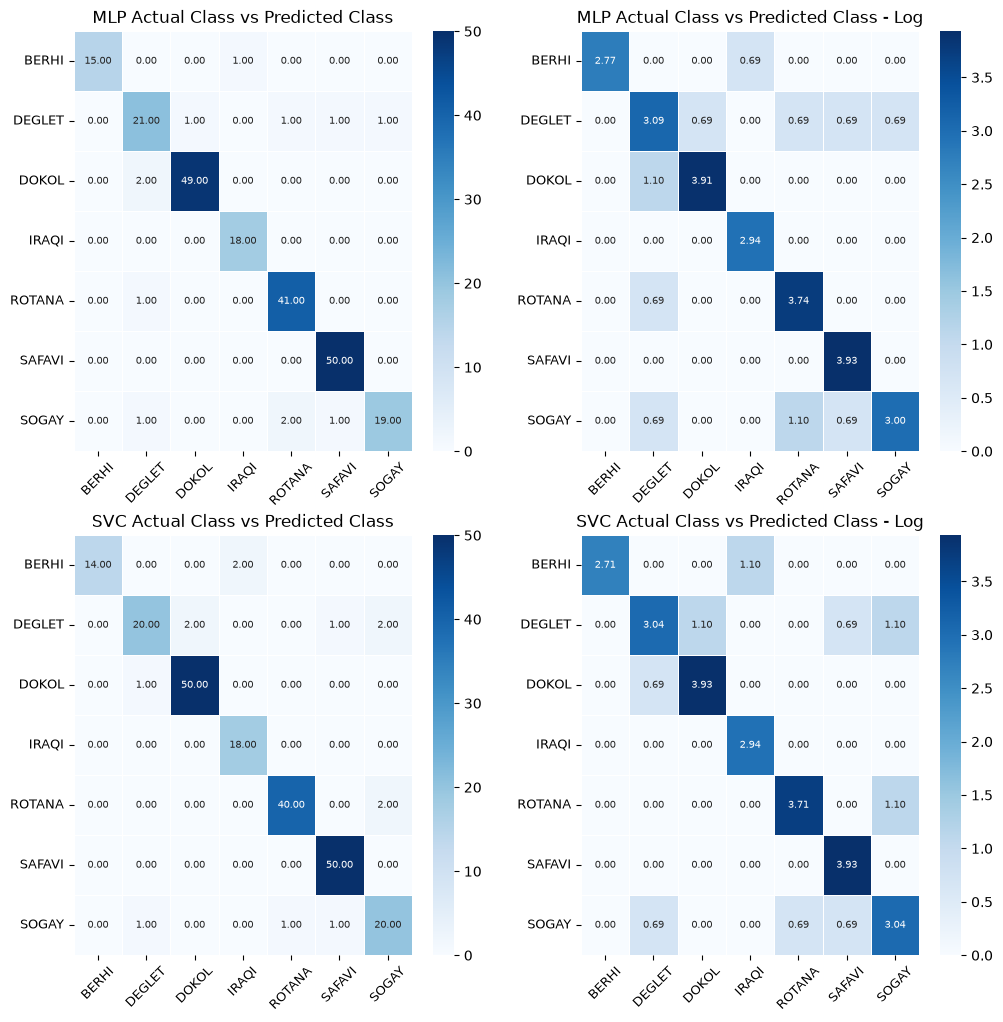

In [12]:
conf_matrx = confusion_matrix(y_test_lab_1, y_pred)
old_conf_matrx = confusion_matrix(y_test_lab_1, old_pred)

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(nrows=2, ncols=2, figsize=(12, 12))
figsize_heatmap = (6, 5)
plot_heatmap(
    dataframe=conf_matrx,
    figsize=figsize_heatmap,
    xticklabels=labels,
    yticklabels=labels,  # pyright: ignore[reportArgumentType]
    cmap="Blues",
    title_name="MLP Actual Class vs Predicted Class",
    ax=ax1,
)
plot_heatmap(
    dataframe=np.log1p(conf_matrx),
    figsize=figsize_heatmap,
    xticklabels=labels,
    yticklabels=labels,  # pyright: ignore[reportArgumentType]
    cmap="Blues",
    title_name="MLP Actual Class vs Predicted Class - Log",
    ax=ax2,
)
plot_heatmap(
    dataframe=old_conf_matrx,
    figsize=figsize_heatmap,
    xticklabels=labels,
    yticklabels=labels,  # pyright: ignore[reportArgumentType]
    cmap="Blues",
    title_name="SVC Actual Class vs Predicted Class",
    ax=ax3,
)
plot_heatmap(
    dataframe=np.log1p(old_conf_matrx),
    figsize=figsize_heatmap,
    xticklabels=labels,
    yticklabels=labels,  # pyright: ignore[reportArgumentType]
    cmap="Blues",
    title_name="SVC Actual Class vs Predicted Class - Log",
    ax=ax4,
)

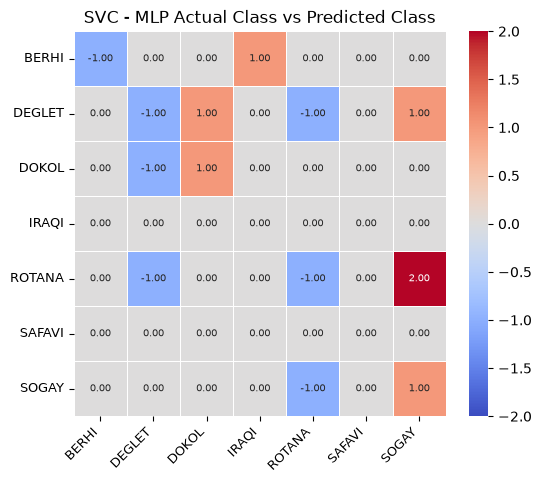

In [13]:
svc_model_result = ModelResult(
    name="SVC",
    confusion_matrix=old_conf_matrx,
    accuracy_score=svc_score,  # pyright: ignore[reportArgumentType]
)


mlp_model_result = ModelResult(
    name="MLP",
    confusion_matrix=conf_matrx,
    accuracy_score=mlp_score,  # pyright: ignore[reportArgumentType]
)

diff_model_result = svc_model_result - mlp_model_result

figsize_heatmap = (6, 5)
plot_heatmap(
    dataframe=diff_model_result.confusion_matrix,
    figsize=figsize_heatmap,
    xticklabels=labels,
    yticklabels=labels,  # pyright: ignore[reportArgumentType]
    cmap="coolwarm",
    title_name="SVC - MLP Actual Class vs Predicted Class",
    vmin=-2,
    vmax=2,
)

## Зробіть висновки

Повнозв'язна нейронна мережа на стандартизованих ознаках досягла тестової точності 0.9467 та макросереднього F1 на рівні 0.94, порівняно з `SVC` із точністю 0.9422 та макросереднім F1 на рівні 0.93 випереджає на один тестовий об'єкт із 225 за однакового обсягу навчальних даних.

Використання окремої валідаційної вибірки, L2-регуляризації та ранньої зупинки дозволило вчасно зафіксувати ваги моделі до початку сильного перенавчання на малій вибірці та отримати об'єктивну оцінку якості на ізольованих тестових даних.

`MLP` без помилок розпізнає всі тестові зразки сортів `'IRAQI'` та `'SAFAVI'`, досягаючи повної чутливості 1.00.
Порівняно з `SVC`, нейромережа точніше класифікує сорти `'BERHI'`, `'DEGLET'` та `'ROTANA'` із перевагою в один об'єкт на кожному класі.
Метод опорних векторів випереджає `MLP` на один приклад у класах `'DOKOL'` та `'SOGAY'`.
Основна частка хибних спрацювань в обох моделей виникає між подібними за ознаками сортами `'DEGLET'`, `'DOKOL'`, `'ROTANA'` та `'SOGAY'`.

# 2. Згорткові нейронні мережі
1. Оберіть датасет зображень для задачі класифікації. 
1. Коротко опишіть датасет (класи, кількість зображень) та візуалізуйте приклади зображень для кожного класу. 
1. Вирішіть задачу класифікації двома способами.
    1. a)
        1. Побудуйте просту CNN (2–3 convolutional шари + fully connected layer).
        1. Навчіть модель на обраному датасеті.
        1. Побудуйте learning curves (train/validation loss) та проаналізуйте процес навчання.
    1. b) 
        1. Використайте попередньо натреновану модель (наприклад, ResNet, EfficientNet, MobileNet або іншу pretrained CNN).
        1. Замініть вихідний класифікатор відповідно до кількості класів вашого датасету та проведіть донавчання моделі.
1. Порівняйте CNN, навчену з нуля, та pretrained модель:  якість класифікації;  процес і швидкість збіжності;  learning curves;  вплив обсягу тренувальних даних.
1. Зробіть висновки.

## Оберіть датасет зображень для задачі класифікації

In [14]:
datapath = Path("../lab3/data/")

transform = transforms.ToTensor()

train_full = datasets.ImageFolder(datapath / "train", transform=transform)
test_dataset = datasets.ImageFolder(datapath / "test", transform=transform)

img_labels_str = train_full.classes
targets = np.array(train_full.targets)
img_labels = np.unique(targets)

def preload_to_device(dataset: datasets.ImageFolder, target_device: torch.device) -> TensorDataset:
    loader = DataLoader(dataset, batch_size=1024, shuffle=False)
    xs, ys = [], []
    for x, y in loader:
        xs.append(x)
        ys.append(y)
    return TensorDataset(torch.cat(xs).to(target_device), torch.cat(ys).to(target_device))

cache_path = datapath / "../train_cache.pt"
if cache_path.exists():
    x_all, y_all = torch.load(cache_path, weights_only=True)
    full_tensor_dataset = TensorDataset(x_all.to(device), y_all.to(device))
else:
    full_tensor_dataset = preload_to_device(train_full, device)
    torch.save(full_tensor_dataset.tensors, cache_path)

generator = torch.Generator().manual_seed(random_state)
train_dataset, val_dataset = random_split(full_tensor_dataset, [0.9, 0.1], generator=generator)

## Коротко опишіть датасет (класи, кількість зображень) та візуалізуйте приклади зображень для кожного класу

2 Classes : ['FAKE', 'REAL']
Image shape: (3, 32, 32)
Train size: 90000, Val size: 10000, Test size: 20000
	FAKE: train_full=50000, test=10000
	REAL: train_full=50000, test=10000


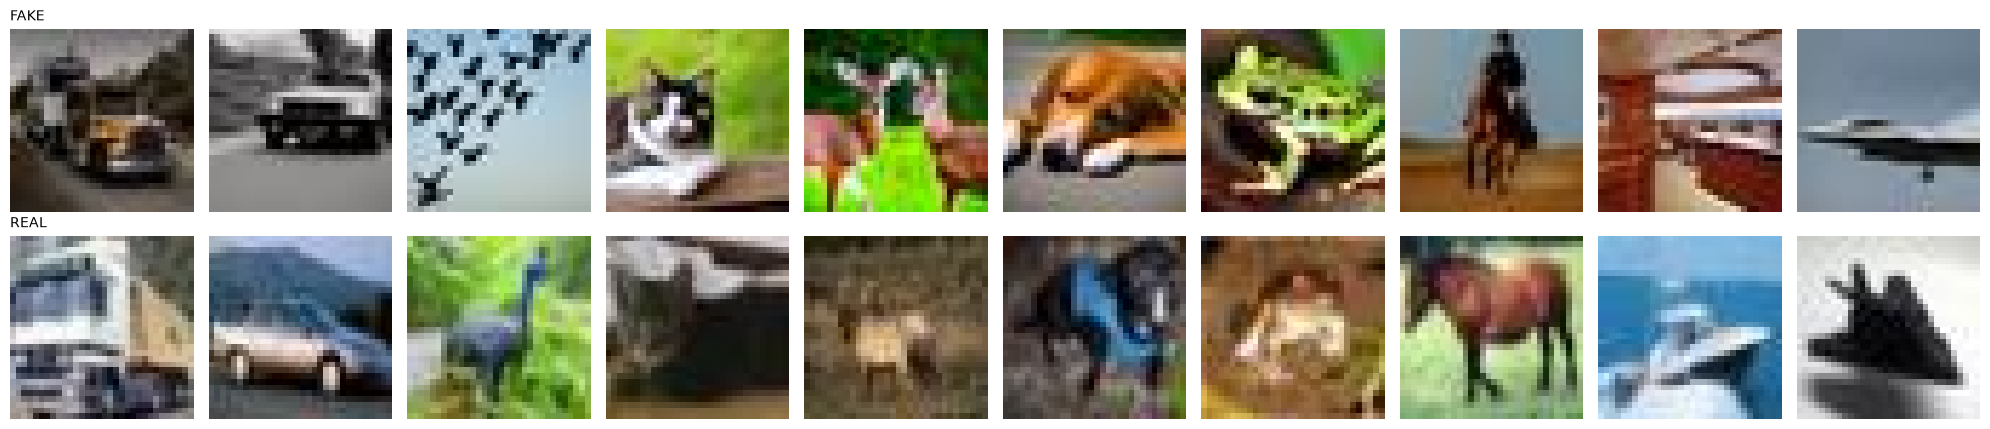

In [15]:
sample_img, _ = train_full[0]
print(f"{len(img_labels_str)} Classes : {img_labels_str}")
print(f"Image shape: {tuple(sample_img.shape)}")
print(
    f"Train size: {len(train_dataset)}, Val size: {len(val_dataset)}, Test size: {len(test_dataset)}"
)

train_counts = np.bincount(train_full.targets)
test_counts = np.bincount(test_dataset.targets)
for idx, class_name in enumerate(img_labels_str):
    print(f"\t{class_name}: train_full={train_counts[idx]}, test={test_counts[idx]}")

n_classes = len(img_labels_str)
n_samples = 10
fig, axes = plt.subplots(
    nrows=n_classes, ncols=n_samples, figsize=(n_samples * 2, n_classes * 2.2)
)
if n_classes == 1:
    axes = np.expand_dims(axes, axis=0)

for row_idx, class_idx in enumerate(img_labels):
    class_indices = np.where(targets == class_idx)[0][:n_samples]
    for col_idx, img_idx in enumerate(class_indices):
        img, _ = train_full[img_idx]
        ax = axes[row_idx, col_idx]
        ax.imshow(img.permute(1, 2, 0))
        ax.axis("off")
        if col_idx == 0:
            ax.set_title(img_labels_str[class_idx], loc="left", fontsize=10)

plt.tight_layout()
plt.show()

## Вирішіть задачу класифікації двома способами

### a)

#### Побудуйте просту CNN (2–3 convolutional шари + fully connected layer)

In [16]:
class CNN(nn.Module):
    def __init__(self, in_features: int, out_features: int):
        super().__init__()
        self.conv1 = nn.Conv2d(in_features, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 4))
        self.dropout = nn.Dropout(0.25)

        self.fc1 = nn.Linear(64 * 4 * 4, 128)
        self.fc2 = nn.Linear(128, out_features)

    def forward(self, x):
        # x: [B, 3, 32, 32]
        x = F.relu(self.conv1(x))  # [B, 32, 32, 32]
        x = self.pool(x)  # [B, 32, 16, 16]
        x = F.relu(self.conv2(x))  # [B, 64, 16, 16]
        x = self.pool(x)  # [B, 64, 8, 8]
        x = self.adaptive_pool(x)  # [B, 64, 4, 4]
        x = self.dropout(x)
        x = torch.flatten(x, 1)  # [B, 64*4*4]
        x = F.relu(self.fc1(x))  # [B, 128]
        logits = self.fc2(x)  # [B, 2]
        return logits


in_features = sample_img.shape[0]
out_features = len(img_labels)
model = CNN(in_features, out_features).to(device)
print(model)

CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (adaptive_pool): AdaptiveAvgPool2d(output_size=(4, 4))
  (dropout): Dropout(p=0.25, inplace=False)
  (fc1): Linear(in_features=1024, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=2, bias=True)
)


#### Навчіть модель на обраному датасеті

In [17]:
model_cnn = CNN(in_features, out_features).to(device)

num_params = sum(p.numel() for p in model_cnn.parameters() if p.requires_grad)
print("Trainable params:", num_params)
print()

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_cnn.parameters(), lr=1e-3, weight_decay=1e-3)

patience = 10
n_epochs = 100
best_model_path_cnn = "best_model_cnn.pth"
batch_size = 256

train_loader_cnn = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader_cnn = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

(
    train_loss_history_cnn,
    train_accuracy_history_cnn,
    val_loss_history_cnn,
    val_accuracy_history_cnn,
) = train_and_eval(
    model_cnn,
    criterion,
    optimizer,
    patience,
    n_epochs,
    best_model_path_cnn,
    len(train_dataset),
    len(val_dataset),
    train_loader_cnn,
    val_loader_cnn,
    device,
)

Trainable params: 150850

[01] train_loss=0.4283 | train_accuracy=0.7963 | val_loss=0.3285 | val_accuracy=0.8651
Saved best model
[02] train_loss=0.3026 | train_accuracy=0.8742 | val_loss=0.2701 | val_accuracy=0.8912
Saved best model
[03] train_loss=0.2601 | train_accuracy=0.8943 | val_loss=0.2404 | val_accuracy=0.9025
Saved best model
[04] train_loss=0.2418 | train_accuracy=0.9027 | val_loss=0.2464 | val_accuracy=0.8972
[05] train_loss=0.2235 | train_accuracy=0.9110 | val_loss=0.2086 | val_accuracy=0.9185
Saved best model
[06] train_loss=0.2090 | train_accuracy=0.9172 | val_loss=0.1929 | val_accuracy=0.9224
Saved best model
[07] train_loss=0.2031 | train_accuracy=0.9197 | val_loss=0.2206 | val_accuracy=0.9089
[08] train_loss=0.1948 | train_accuracy=0.9237 | val_loss=0.2058 | val_accuracy=0.9147
[09] train_loss=0.1882 | train_accuracy=0.9261 | val_loss=0.1702 | val_accuracy=0.9340
Saved best model
[10] train_loss=0.1843 | train_accuracy=0.9280 | val_loss=0.1702 | val_accuracy=0.9353
[1

#### Побудуйте learning curves (train/validation loss) та проаналізуйте процес навчання

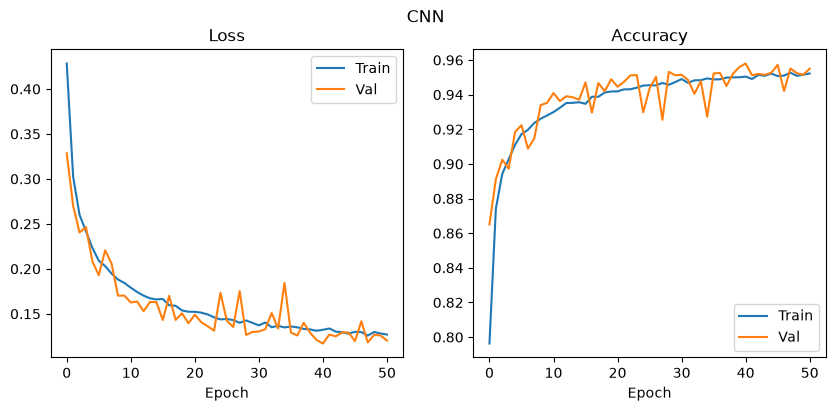

In [18]:
plot_learning_curves(
    train_loss_history_cnn,
    train_accuracy_history_cnn,
    val_loss_history_cnn,
    val_accuracy_history_cnn,
    title="CNN",
)

### b)

#### Використайте попередньо натреновану модель (наприклад, ResNet, EfficientNet, MobileNet або іншу pretrained CNN)

In [19]:
class PretrainedResNet(nn.Module):
    def __init__(self, out_features: int, img_size: int = 96):
        super().__init__()
        self.img_size = img_size
        self.register_buffer(
            "mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        )
        self.register_buffer(
            "std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        )   

        self.backbone = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        in_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Linear(in_features, out_features)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = F.interpolate(
            x,
            size=(self.img_size, self.img_size),
            mode="bilinear",
            align_corners=False,
        )
        x = (x - self.mean) / self.std # type: ignore
        return self.backbone(x)

#### Замініть вихідний класифікатор відповідно до кількості класів вашого датасету та проведіть донавчання моделі

In [20]:
model_resnet = PretrainedResNet(out_features=len(img_labels), img_size=96).to(device)

num_params = sum(p.numel() for p in model_resnet.parameters() if p.requires_grad)
print("Trainable params:", num_params)
print()

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_resnet.parameters(), lr=1e-4, weight_decay=1e-3)

patience = 10
n_epochs = 100
best_model_path_resnet = "best_model_resnet.pth"
batch_size = 256

(
    train_loss_history_resnet,
    train_accuracy_history_resnet,
    val_loss_history_resnet,
    val_accuracy_history_resnet,
) = train_and_eval(
    model_resnet,
    criterion,
    optimizer,
    patience,
    n_epochs,
    best_model_path_resnet,
    len(train_dataset),
    len(val_dataset),
    train_loader_cnn,
    val_loader_cnn,
    device,
)

Trainable params: 11177538

[01] train_loss=0.1098 | train_accuracy=0.9560 | val_loss=0.0623 | val_accuracy=0.9765
Saved best model
[02] train_loss=0.0304 | train_accuracy=0.9890 | val_loss=0.0629 | val_accuracy=0.9763
[03] train_loss=0.0169 | train_accuracy=0.9942 | val_loss=0.0888 | val_accuracy=0.9735
[04] train_loss=0.0171 | train_accuracy=0.9939 | val_loss=0.0756 | val_accuracy=0.9750
[05] train_loss=0.0152 | train_accuracy=0.9944 | val_loss=0.0760 | val_accuracy=0.9756
[06] train_loss=0.0151 | train_accuracy=0.9944 | val_loss=0.0771 | val_accuracy=0.9775
[07] train_loss=0.0139 | train_accuracy=0.9950 | val_loss=0.0678 | val_accuracy=0.9786
[08] train_loss=0.0138 | train_accuracy=0.9951 | val_loss=0.0767 | val_accuracy=0.9759
[09] train_loss=0.0133 | train_accuracy=0.9954 | val_loss=0.0787 | val_accuracy=0.9769
[10] train_loss=0.0128 | train_accuracy=0.9955 | val_loss=0.0711 | val_accuracy=0.9772
[11] train_loss=0.0125 | train_accuracy=0.9955 | val_loss=0.0643 | val_accuracy=0.978

## Порівняйте CNN, навчену з нуля, та pretrained модель:  якість класифікації;  процес і швидкість збіжності;  learning curves;  вплив обсягу тренувальних даних

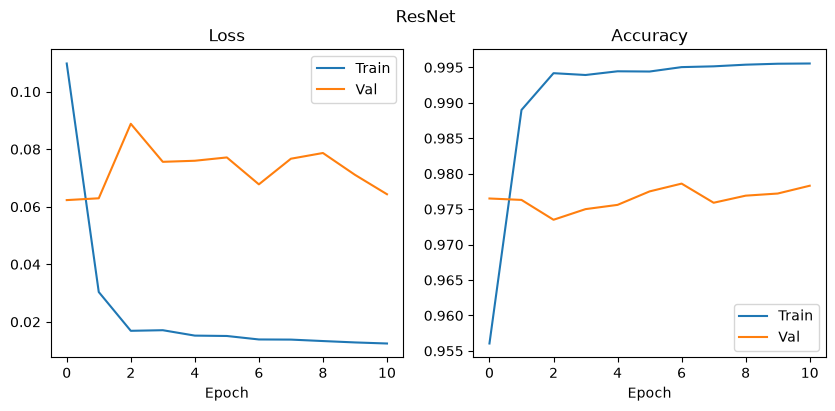

In [21]:
plot_learning_curves(
    train_loss_history_resnet,
    train_accuracy_history_resnet,
    val_loss_history_resnet,
    val_accuracy_history_resnet,
    title="ResNet",
)

In [22]:
test_cache_path = datapath / "../test_cache_path.pt"
if test_cache_path.exists():
    x_all, y_all = torch.load(test_cache_path, weights_only=True)
    test_tensor_dataset = TensorDataset(x_all.to(device), y_all.to(device))
else:
    test_tensor_dataset = preload_to_device(test_dataset, device)
    torch.save(test_tensor_dataset.tensors, test_cache_path)

test_loader_cnn = DataLoader(test_tensor_dataset, batch_size=512, shuffle=False)


def predict_classes(model: nn.Module, loader: DataLoader) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    preds, targets_all = [], []
    with torch.no_grad():
        for x, y in loader:
            out = model(x)
            preds.append(out.argmax(dim=1).cpu().numpy())
            targets_all.append(y.cpu().numpy())
    return np.concatenate(targets_all), np.concatenate(preds)


model_cnn.load_state_dict(torch.load(best_model_path_cnn, weights_only=True))
y_true_img, y_pred_cnn = predict_classes(model_cnn, test_loader_cnn)

model_resnet.load_state_dict(torch.load(best_model_path_resnet, weights_only=True))
_, y_pred_resnet = predict_classes(model_resnet, test_loader_cnn)

cnn_score = accuracy_score(y_true_img, y_pred_cnn)
print(f"CNN Test accuracy: {cnn_score:.4f}")
print(classification_report(y_true_img, y_pred_cnn, target_names=img_labels_str))

resnet_score = accuracy_score(y_true_img, y_pred_resnet)
print(f"ResNet18 Test accuracy: {resnet_score:.4f}")
print(classification_report(y_true_img, y_pred_resnet, target_names=img_labels_str))

CNN Test accuracy: 0.9563
              precision    recall  f1-score   support

        FAKE       0.95      0.96      0.96     10000
        REAL       0.96      0.95      0.96     10000

    accuracy                           0.96     20000
   macro avg       0.96      0.96      0.96     20000
weighted avg       0.96      0.96      0.96     20000

ResNet18 Test accuracy: 0.9765
              precision    recall  f1-score   support

        FAKE       0.98      0.98      0.98     10000
        REAL       0.98      0.98      0.98     10000

    accuracy                           0.98     20000
   macro avg       0.98      0.98      0.98     20000
weighted avg       0.98      0.98      0.98     20000



In [23]:
small_generator = torch.Generator().manual_seed(random_state)
small_train_dataset, _ = random_split(train_dataset, [0.1, 0.9], generator=small_generator)
small_train_loader = DataLoader(small_train_dataset, batch_size=batch_size, shuffle=True)

In [24]:
patience = 10
n_epochs = 100
batch_size = 256

in_features = sample_img.shape[0]
out_features = len(img_labels)
small_model_cnn = CNN(in_features, out_features).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(small_model_cnn.parameters(), lr=1e-3, weight_decay=1e-3)

best_model_path_small_cnn = "small_best_model_cnn.pth"
(
    small_train_loss_history_cnn,
    small_train_accuracy_history_cnn,
    small_val_loss_history_cnn,
    small_val_accuracy_history_cnn,
) = train_and_eval(
    small_model_cnn,
    criterion,
    optimizer,
    patience,
    n_epochs,
    best_model_path_small_cnn,
    len(small_train_dataset),
    len(val_dataset),
    small_train_loader,
    val_loader_cnn,
    device,
)

small_model_resnet = PretrainedResNet(out_features=len(img_labels), img_size=96).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(small_model_resnet.parameters(), lr=1e-4, weight_decay=1e-3)

best_model_path_small_resnet = "small_best_model_resnet.pth"
(
    small_train_loss_history_resnet,
    small_train_accuracy_history_resnet,
    small_val_loss_history_resnet,
    small_val_accuracy_history_resnet,
) = train_and_eval(
    small_model_resnet,
    criterion,
    optimizer,
    patience,
    n_epochs,
    best_model_path_small_resnet,
    len(small_train_dataset),
    len(val_dataset),
    small_train_loader,
    val_loader_cnn,
    device,
)

[01] train_loss=0.6489 | train_accuracy=0.6127 | val_loss=0.5748 | val_accuracy=0.7088
Saved best model
[02] train_loss=0.5199 | train_accuracy=0.7371 | val_loss=0.4734 | val_accuracy=0.7788
Saved best model
[03] train_loss=0.4534 | train_accuracy=0.7842 | val_loss=0.4282 | val_accuracy=0.8041
Saved best model
[04] train_loss=0.4144 | train_accuracy=0.8142 | val_loss=0.3996 | val_accuracy=0.8163
Saved best model
[05] train_loss=0.3920 | train_accuracy=0.8252 | val_loss=0.3723 | val_accuracy=0.8368
Saved best model
[06] train_loss=0.3657 | train_accuracy=0.8429 | val_loss=0.3708 | val_accuracy=0.8522
Saved best model
[07] train_loss=0.3687 | train_accuracy=0.8416 | val_loss=0.3502 | val_accuracy=0.8481
Saved best model
[08] train_loss=0.3546 | train_accuracy=0.8466 | val_loss=0.3481 | val_accuracy=0.8514
Saved best model
[09] train_loss=0.3396 | train_accuracy=0.8586 | val_loss=0.3304 | val_accuracy=0.8592
Saved best model
[10] train_loss=0.3213 | train_accuracy=0.8657 | val_loss=0.3432

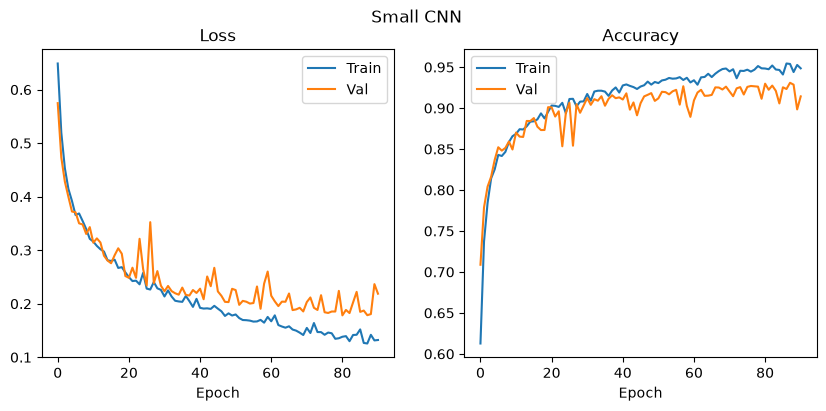

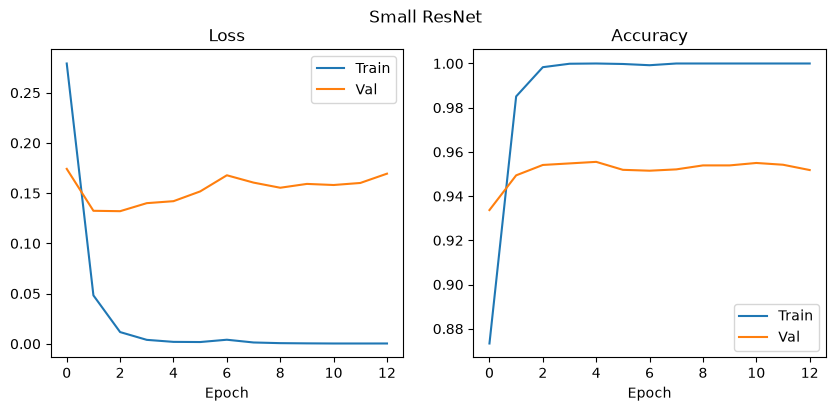

In [25]:
plot_learning_curves(
    small_train_loss_history_cnn,
    small_train_accuracy_history_cnn,
    small_val_loss_history_cnn,
    small_val_accuracy_history_cnn,
    title="Small CNN",
)
plot_learning_curves(
    small_train_loss_history_resnet,
    small_train_accuracy_history_resnet,
    small_val_loss_history_resnet,
    small_val_accuracy_history_resnet,
    title="Small ResNet",
)

In [26]:
small_model_cnn.load_state_dict(torch.load(best_model_path_small_cnn, weights_only=True))
y_true_img, small_y_pred_cnn = predict_classes(small_model_cnn, test_loader_cnn)

small_model_resnet.load_state_dict(torch.load(best_model_path_small_resnet, weights_only=True))
_, small_y_pred_resnet = predict_classes(small_model_resnet, test_loader_cnn)

small_cnn_score = accuracy_score(y_true_img, small_y_pred_cnn)
print(f"Small CNN Test accuracy: {small_cnn_score:.4f}")
print(classification_report(y_true_img, small_y_pred_cnn, target_names=img_labels_str))

small_resnet_score = accuracy_score(y_true_img, small_y_pred_resnet)
print(f"Small ResNet18 Test accuracy: {small_resnet_score:.4f}")
print(classification_report(y_true_img, small_y_pred_resnet, target_names=img_labels_str))

Small CNN Test accuracy: 0.9238
              precision    recall  f1-score   support

        FAKE       0.94      0.91      0.92     10000
        REAL       0.91      0.94      0.92     10000

    accuracy                           0.92     20000
   macro avg       0.92      0.92      0.92     20000
weighted avg       0.92      0.92      0.92     20000

Small ResNet18 Test accuracy: 0.9557
              precision    recall  f1-score   support

        FAKE       0.96      0.95      0.96     10000
        REAL       0.95      0.96      0.96     10000

    accuracy                           0.96     20000
   macro avg       0.96      0.96      0.96     20000
weighted avg       0.96      0.96      0.96     20000



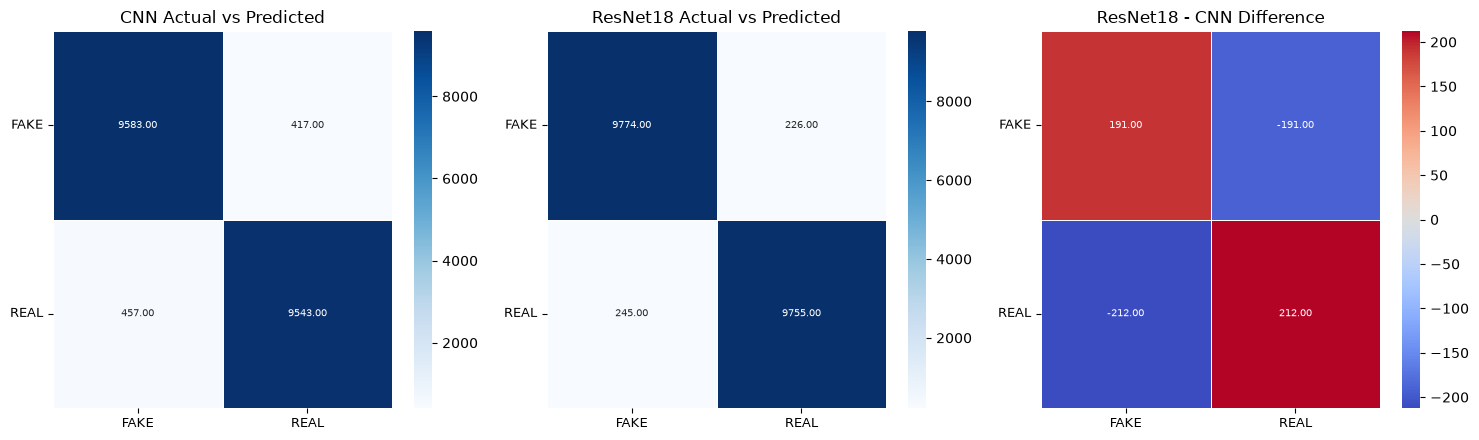

In [31]:
cm_cnn = confusion_matrix(y_true_img, y_pred_cnn)
cm_resnet = confusion_matrix(y_true_img, y_pred_resnet)

cnn_model_result = ModelResult(
    name="CNN",
    confusion_matrix=cm_cnn,
    accuracy_score=float(cnn_score),
)
resnet_model_result = ModelResult(
    name="ResNet18",
    confusion_matrix=cm_resnet,
    accuracy_score=float(resnet_score),
)
diff_img_result = resnet_model_result - cnn_model_result
max_diff = float(np.abs(diff_img_result.confusion_matrix).max())

fig, (ax1, ax2, ax3) = plt.subplots(ncols=3, figsize=(15, 4.5))

plot_heatmap(
    dataframe=cm_cnn,
    xticklabels=img_labels_str,
    yticklabels=img_labels_str,
    cmap="Blues",
    title_name="CNN Actual vs Predicted",
    ax=ax1,
    rotation=0
)
plot_heatmap(
    dataframe=cm_resnet,
    xticklabels=img_labels_str,
    yticklabels=img_labels_str,
    cmap="Blues",
    title_name="ResNet18 Actual vs Predicted",
    ax=ax2,
    rotation=0
)
plot_heatmap(
    dataframe=diff_img_result.confusion_matrix,
    xticklabels=img_labels_str,
    yticklabels=img_labels_str,
    cmap="coolwarm",
    vmin=-max_diff,
    vmax=max_diff,
    title_name="ResNet18 - CNN Difference",
    ax=ax3,
    rotation=0
)

plt.tight_layout()
plt.show()

**Якість класифікації.** Попередньо навчена модель забезпечує вищу точність та кращий баланс між влучністю й повнотою на тестовій вибірці. Згорткова мережа з випадковою ініціалізацією ваг змушена виділяти базові візуальні примітиви самостійно, через що частіше помиляється на складних прикладах. Попередньо навчена архітектура вже має сформовані фільтри для виявлення контурів, текстур і просторових структур, тому краще розпізнає дрібні спотворення та специфічні ознаки класів.

**Процес і швидкість збіжності.** Навчання з нуля потребує значно більше епох для стабілізації градієнтів, оскільки нижні згорткові шари довго налаштовують базові детектори ознак, і лише після цього класифікатор починає будувати розділяючу межу. Попередньо навчена модель стартує з уже впорядкованого простору ознак, тому функція втрат стрімко знижується вже протягом перших кількох епох, а оптимізація зводиться до адаптації верхніх шарів під конкретну задачу.

**Криві навчання.** У мережі, навченій з нуля, тренувальні втрати знижуються повільно, а валідаційна крива демонструє помітні коливання та раніше виходить на плато, після чого зростає розрив через перенавчання. У попередньо навченої моделі обидві криві швидко досягають низьких значень втрат і високої точності, а розходження між тренувальною та валідаційною вибірками залишається меншим за умови правильного вибору кроку навчання.

**Вплив обсягу тренувальних даних.** На обмеженому наборі зображень згорткова мережа з нуля швидко запам'ятовує конкретні тренувальні приклади замість вивчення загальних закономірностей, що знижує узагальнювальну здатність. Попередньо навчена модель значно стійкіша до нестачі даних, адже спирається на представлення, сформовані на великих зовнішніх корпусах зображень, і потребує порівняно невеликої вибірки для тонкого налаштування класифікатора.

## Зробіть висновки

Для задач класифікації зображень із обмеженим обсягом даних перенесення навчання переважає побудову згорткових мереж з нуля як за підсумковою якістю розпізнавання, так і за витратами часу на навчання. Використання попередньо навчених ваг знижує ризик швидкого перенавчання на малих вибірках і забезпечує стабільну збіжність уже на початкових епохах. Навчання власної архітектури з випадкової ініціалізації виправдане лише за наявності великого спеціалізованого набору даних, візуальна структура якого суттєво відрізняється від звичайних фотографій.

# 3. Нейронні мережі для класифікації текстів
1. Використайте той самий текстовий датасет, з яким ви працювали в лабораторній роботі №2.
1. Проведіть необхідну передобробку текстових даних: токенізацію, побудову словника, перетворення токенів в індекси та приведення послідовностей до однакової довжини (padding/truncation).
1. Вирішіть задачу класифікації двома способами.
1. 
    1. а)
        1. Побудуйте модель з Embedding layer, ініціалізованим випадковими вагами.
        1. Використайте RNN / LSTM / GRU для класифікації та навчіть модель на своєму датасеті.
    1. б)
        1. Завантажте готові pretrained embeddings (наприклад, GloVe) та ініціалізуйте ними Embedding layer.
        1. Проведіть навчання моделі.
1. Для обох моделей побудуйте learning curves (train/validation loss).
1. Порівняйте результати двох підходів:  якість класифікації;  швидкість і стабільність навчання;  вплив pretrained embeddings на отриманий результат.
1. Зробіть висновки.

## Використайте той самий текстовий датасет, з яким ви працювали в лабораторній роботі №2

In [28]:
import re

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

datapath_lab_2 = Path("../lab2/data/train.csv")
raw_data_lab_2 = pd.read_csv(datapath_lab_2)

raw_texts = raw_data_lab_2["text"]
targets = raw_data_lab_2["model"]
text_labels = np.sort(targets.unique())

raw_train, raw_test, targets_train, targets_test = train_test_split(
    raw_texts,
    targets,
    random_state=random_state,
    test_size=0.15,
    stratify=targets,
)

## Проведіть необхідну передобробку текстових даних: токенізацію, побудову словника, перетворення токенів в індекси та приведення послідовностей до однакової довжини (padding/truncation)

In [29]:
def extract_style_features(texts: pd.Series) -> np.ndarray:
    feats = []
    for text in texts:
        length = max(len(text), 1)
        words = text.split()
        n_words = max(len(words), 1)
        sentences = [s for s in re.split(r"[.!?]+", text) if s.strip()]
        n_sents = max(len(sentences), 1)

        feats.append(
            [
                np.log1p(length),  # total character length
                np.log1p(n_words),  # total word count
                length / n_words,  # average word length
                n_words / n_sents,  # average sentence length (rhythm)
                text.count(",") / n_words,  # comma density (clause complexity)
                text.count(";") / n_words,  # semicolon usage
                text.count(":") / n_words,  # colon usage
                text.count("—") / n_words,  # em-dash usage
                text.count(" — ") / n_words,  # em-dash usage
                (text.count("’") + text.count("“") + text.count("”"))
                / n_words,  # curly quotes
                (text.count("'") + text.count('"')) / n_words,  # straight quotes
                sum(c.isupper() for c in text) / length,  # uppercase ratio
                sum(c.isdigit() for c in text) / length,  # digit ratio
            ]
        )
    return np.array(feats, dtype=np.float32)


vectorizer = FeatureUnion(
    transformer_list=[
        (
            "word",
            TfidfVectorizer(
                lowercase=False,
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.95,
                sublinear_tf=True,
                token_pattern=r"\S+",
            ),
        ),
        (
            "char",
            TfidfVectorizer(
                lowercase=False,
                analyzer="char",
                ngram_range=(3, 5),
                min_df=5,
                max_df=0.95,
                sublinear_tf=True,
            ),
        ),
        (
            "style",
            Pipeline(
                [
                    (
                        "extract",
                        FunctionTransformer(extract_style_features, validate=False),
                    ),
                    ("scale", StandardScaler()),
                ]
            ),
        ),
    ],  # type: ignore
    transformer_weights={"word": 1.0, "char": 1.0, "style": 0.25},
)

## Вирішіть задачу класифікації двома способами

### a)

#### Побудуйте модель з Embedding layer, ініціалізованим випадковими вагами

#### Використайте RNN / LSTM / GRU для класифікації та навчіть модель на своєму датасеті

In [30]:
pipe_RNN = Pipeline(
    [
        ("vec", vectorizer),
        ("clf", LogisticRegression(max_iter=1000, random_state=random_state)),
    ]
)

pipe_LSTM = Pipeline(
    [
        ("vec", vectorizer),
        ("clf", LogisticRegression(max_iter=1000, random_state=random_state)),
    ]
)

pipe_GRU = Pipeline(
    [
        ("vec", vectorizer),
        ("clf", LogisticRegression(max_iter=1000, random_state=random_state)),
    ]
)

### b)

#### Завантажте готові pretrained embeddings (наприклад, GloVe) та ініціалізуйте ними Embedding layer

#### Проведіть навчання моделі

## Для обох моделей побудуйте learning curves (train/validation loss)

## Порівняйте результати двох підходів:  якість класифікації;  швидкість і стабільність навчання;  вплив pretrained embeddings на отриманий результат

## Зробіть висновки